# Calibração

**Objetivo:** fazer a probabilidade do modelo bater com a taxa real de fraude. A Etapa 7 multiplica essa probabilidade pelo valor da compra, então ela precisa estar certa.

**Como (D17 e D18):**
- A validação é dividida em duas metades no tempo.
- A primeira metade ajusta a calibração de Platt, uma regressão logística de 2 parâmetros sobre a pontuação do modelo.
- A segunda metade mede o resultado. Ela também será usada na Etapa 7.

**Modelos:** LightGBM sem agregações, com e sem colunas C (D11 e D16). O teste não entra em nenhum cálculo.

In [1]:
from pathlib import Path
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
from divisao_temporal import calcular_cortes, dividir_por_tempo
from modelo import treinar_lightgbm

ARQUIVO = RAIZ / "data" / "processed" / "treino.parquet"
nomes = pq.ParquetFile(ARQUIVO).schema_arrow.names
COLUNAS_C = [n for n in nomes if re.fullmatch(r"C\d+", n)]
COLUNAS_ID = [n for n in nomes if re.fullmatch(r"id_\d+", n)]
COLUNAS_BASE = [
    "TransactionAmt", "tem_identidade", "ProductCD", "card4", "card6",
    "card1", "card2", "card3", "card5", "addr1", "addr2", "dist1", "dist2",
    "P_emaildomain", "R_emaildomain",
]

tabela = pd.read_parquet(
    ARQUIVO,
    columns=["TransactionDT", "isFraud", *[c for c in COLUNAS_BASE if c != "tem_identidade"], *COLUNAS_C, *COLUNAS_ID],
)
tabela["tem_identidade"] = tabela[COLUNAS_ID].notna().any(axis=1).astype("int8")
tabela = tabela.drop(columns=COLUNAS_ID)

corte_treino, corte_validacao = calcular_cortes(tabela["TransactionDT"])
treino, validacao, _ = dividir_por_tempo(tabela, corte_treino, corte_validacao)
del _, tabela  # o teste sai da memória antes de qualquer treino ou medição

corte_metade, _ = calcular_cortes(validacao["TransactionDT"], fracao_treino=0.5, fracao_validacao=0.5)
calibra, mede, _ = dividir_por_tempo(validacao, corte_metade, validacao["TransactionDT"].max())
del _

pd.DataFrame(
    {
        nome: {"Transações": len(parte), "Fraudes": int(parte["isFraud"].sum()), "Taxa de fraude (%)": round(100 * parte["isFraud"].mean(), 2)}
        for nome, parte in [("Treino", treino), ("1ª metade (calibra)", calibra), ("2ª metade (mede)", mede)]
    }
).T

,Transações,Fraudes,Taxa de fraude (%)
Treino,354324.0,11988.0,3.38
1ª metade (calibra),59054.0,2550.0,4.32
2ª metade (mede),59054.0,2061.0,3.49


## 1. Treino e calibração

O LightGBM é treinado como no notebook 05. A PR-AUC na validação inteira serve para conferir que o modelo é o mesmo: 0,5742 com C e 0,2806 sem C.

A calibração de Platt trabalha com o logit da probabilidade, `log(p / (1 - p))`, e aprende só a inclinação e o deslocamento. Como a função é crescente, a ordem das compras não muda.

In [2]:
def logit(p: np.ndarray) -> np.ndarray:
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


previsoes = {}
for nome, colunas in [("Com C", [*COLUNAS_BASE, *COLUNAS_C]), ("Sem C", COLUNAS_BASE)]:
    modelo, arvores = treinar_lightgbm(treino, colunas)
    p_validacao = modelo.predict(validacao[colunas])
    print(f"{nome}: {arvores} árvores | PR-AUC na validação inteira: {average_precision_score(validacao['isFraud'], p_validacao):.4f}")

    p_calibra = modelo.predict(calibra[colunas])
    p_mede = modelo.predict(mede[colunas])
    # C alto deixa a regressão sem penalidade, como no Platt original.
    platt = LogisticRegression(C=1e10).fit(logit(p_calibra), calibra["isFraud"])
    print(f"   inclinação {platt.coef_[0, 0]:.3f} | deslocamento {platt.intercept_[0]:.3f}")
    previsoes[nome] = {
        "sem calibrar": pd.Series(p_mede, index=mede.index),
        "calibrada": pd.Series(platt.predict_proba(logit(p_mede))[:, 1], index=mede.index),
    }

Com C: 712 árvores | PR-AUC na validação inteira: 0.5742


   inclinação 0.922 | deslocamento 0.201


Sem C: 344 árvores | PR-AUC na validação inteira: 0.2806


   inclinação 0.952 | deslocamento 0.158


## 2. Resultado na 2ª metade

- **Brier:** quanto menor, melhor. A referência usa a taxa de fraude da 1ª metade como probabilidade para todas as compras.
- **Probabilidade média:** numa calibração boa, fica perto da taxa real.
- **PR-AUC:** deve ficar igual antes e depois, porque a calibração não muda a ordem.

In [3]:
rotulos = mede["isFraud"].astype("int8")
linhas = [
    {
        "Modelo": "Referência (taxa da 1ª metade)",
        "Brier": brier_score_loss(rotulos, np.full(len(rotulos), calibra["isFraud"].mean())),
        "Probabilidade média (%)": 100 * calibra["isFraud"].mean(),
        "Taxa real (%)": 100 * rotulos.mean(),
        "PR-AUC": np.nan,
    }
]
for nome, versoes in previsoes.items():
    for versao, p in versoes.items():
        linhas.append(
            {
                "Modelo": f"{nome}, {versao}",
                "Brier": brier_score_loss(rotulos, p),
                "Probabilidade média (%)": 100 * p.mean(),
                "Taxa real (%)": 100 * rotulos.mean(),
                "PR-AUC": average_precision_score(rotulos, p),
            }
        )
pd.DataFrame(linhas).set_index("Modelo").round(4)

,Brier,Probabilidade média (%),Taxa real (%),PR-AUC
Modelo,,,,
Referência (taxa da 1ª metade),0.0338,4.3181,3.49,NaN
"Com C, sem calibrar",0.0213,2.8188,3.49,0.5461
"Com C, calibrada",0.0212,3.5659,3.49,0.5461
"Sem C, sem calibrar",0.0292,2.8086,3.49,0.2657
"Sem C, calibrada",0.0291,3.5827,3.49,0.2657


## 3. Calibração por faixa

As compras da 2ª metade são ordenadas pela probabilidade e divididas em 10 faixas do mesmo tamanho (decis). A faixa 10 tem as compras com maior chance de fraude. Numa calibração boa, a probabilidade média de cada faixa fica perto da taxa real dela.

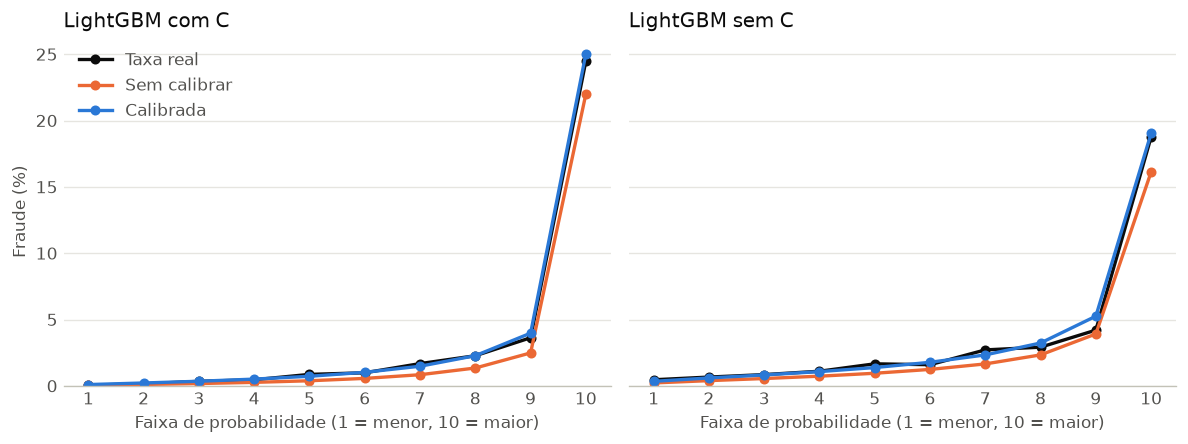

Com C                                        Sem C  \
      Taxa real (%) Sem calibrar (%) Calibrada (%) Taxa real (%)   
Faixa                                                              
1              0.05             0.04          0.10          0.46   
2              0.15             0.10          0.21          0.66   
3              0.34             0.17          0.35          0.85   
4              0.46             0.26          0.51          1.10   
5              0.86             0.38          0.72          1.66   
6              0.98             0.56          1.02          1.59   
7              1.68             0.84          1.48          2.71   
8              2.27             1.34          2.27          2.91   
9              3.62             2.48          3.97          4.20   
10            24.48            22.00         25.03         18.76   

                                      
      Sem calibrar (%) Calibrada (%)  
Faixa                                 
1                 0.22          0.34  
2                 0.39          0.59  
3                 0.55          0.82  
4                 0.73          1.07  
5                 0.95          1.38  
6                 1.24          1.77  
7                 1.65          2.33  
8                 2.33          3.23  
9                 3.91          5.25  
10               16.12         19.04

In [4]:
tabelas_decis = {}
for nome, versoes in previsoes.items():
    faixa = pd.qcut(versoes["calibrada"].rank(method="first"), 10, labels=range(1, 11))
    tabelas_decis[nome] = pd.DataFrame(
        {
            "Taxa real (%)": 100 * rotulos.groupby(faixa, observed=True).mean(),
            "Sem calibrar (%)": 100 * versoes["sem calibrar"].groupby(faixa, observed=True).mean(),
            "Calibrada (%)": 100 * versoes["calibrada"].groupby(faixa, observed=True).mean(),
        }
    ).rename_axis("Faixa")

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.8), dpi=120, sharey=True)
for ax, (nome, decis) in zip(eixos, tabelas_decis.items()):
    for coluna, cor in [("Taxa real (%)", "#0b0b0b"), ("Sem calibrar (%)", "#eb6834"), ("Calibrada (%)", "#2a78d6")]:
        ax.plot(decis.index.astype(int), decis[coluna], color=cor, linewidth=2, marker="o", markersize=5, label=coluna.replace(" (%)", ""))
    ax.set_title(f"LightGBM {nome[0].lower() + nome[1:]}", loc="left", color="#0b0b0b")
    ax.set_xlabel("Faixa de probabilidade (1 = menor, 10 = maior)", color="#52514e")
    ax.set_xticks(range(1, 11))
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors="#52514e", length=0)
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
eixos[0].set_ylabel("Fraude (%)", color="#52514e")
eixos[0].legend(frameon=False, labelcolor="#52514e")
fig.tight_layout()
plt.show()

pd.concat(tabelas_decis, axis=1).round(2)

## Conclusões da calibração

- Sem calibração, o modelo previa menos fraude do que a realidade. Na 2ª metade da validação, a probabilidade média era de 2,82% com C e 2,81% sem C, para uma taxa real de 3,49%. O modelo aprendeu num treino com 3,38% de fraude, e a validação tem taxa maior.
- A calibração aproximou a média da realidade: 3,57% com C e 3,58% sem C, cerca de 0,1 ponto acima da taxa real. A sobra vem da mudança entre as metades: a calibração aprendeu num período com 4,32% de fraude e foi medida num período com 3,49%.
- Por faixa, a calibrada fica mais perto da taxa real na maioria das faixas. Na faixa 10 do modelo com C, a taxa real é 24,48%, contra 22,00% sem calibrar e 25,03% calibrada.
- O Brier quase não muda: de 0,0213 para 0,0212 com C, e de 0,0292 para 0,0291 sem C. O ganho da calibração está na média das probabilidades, que a Etapa 7 usa para estimar valor.
- A PR-AUC fica igual antes e depois (0,5461 com C e 0,2657 sem C), porque a calibração de Platt é uma função crescente: muda os números, mas não a ordem das compras. A PR-AUC só depende da ordem.
- **Limites:** a calibração usa uma metade da validação, com 2.550 fraudes. A taxa de fraude muda de um período para outro, então uma calibração ajustada num período tende a errar um pouco no seguinte. Em produção, ela precisaria ser refeita com frequência. O teste não foi usado.